<a href="https://colab.research.google.com/github/memo10m/new_test/blob/main/neural_networks_1st_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Environment Setup


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler



In [ ]:
import os
from google.colab import drive

# 1. Mount the drive
drive.mount('/content/drive')

# 2. Define the path (Use quotes because of the spaces in folder names)
folder_path = '/content/drive/MyDrive/neural networks assignments/Assignment 1'

# 3. List the files to make sure it works
print(os.listdir(folder_path))

# 4. (Optional) Change directory to this folder
%cd /content/drive/MyDrive/neural\ networks\ assignments/Assignment\ 1


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['Copy of check_accuracy.p', 'Copy of Indian_Digits_Train.zip']
/content/drive/MyDrive/neural networks assignments/Assignment 1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##un_zip stage


In [ ]:
# 1. Define the path to your zip file
zip_path = '/content/drive/MyDrive/neural networks assignments/Assignment 1/Copy of Indian_Digits_Train.zip'

# 2. Unzip it to the local Colab disk (/content/)
# This is MUCH faster for training than reading from Drive
!unzip -q "{zip_path}" -d /content/dataset/

# 3. Now you can access your images at:
# /content/dataset/

replace /content/dataset/Indian_Digits_Train/1.bmp? [y]es, [n]o, [A]ll, [N]one, [r]ename: N


#2. Data Loading & Preprocessing


In [ ]:
from tqdm import tqdm

def load_images(folder_path):
    images = []
    # Using tqdm for a visual progress bar
    for i in tqdm(range(1, 10001), desc="Loading Images"):
        img_path = os.path.join(folder_path, f"{i}.bmp")
        if os.path.exists(img_path):
            img = Image.open(img_path).convert('L')
            images.append(np.array(img).flatten())
        else:
            print(f"Warning: Missing file {img_path}")
    return np.array(images)


X_raw = load_images('/content/dataset/Indian_Digits_Train')


Loading Images: 100%|██████████| 10000/10000 [00:02<00:00, 4659.80it/s]


##Verify Data Dimensions

In [ ]:
print(f"Data successfully loaded.")
print(f"Total images: {X_raw.shape[0]}")  # Should be 10000
print(f"Features per image: {X_raw.shape[1]}")  # Should be 784

Data successfully loaded.
Total images: 10000
Features per image: 784


##Visual Confirmation (Sanity Check)

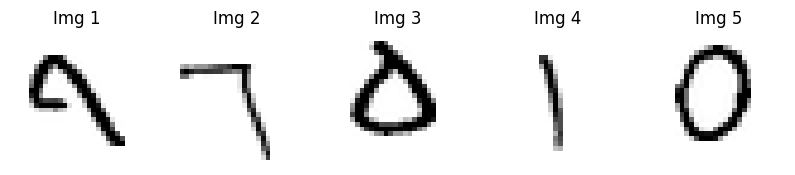

In [ ]:
def plot_samples(data, num_samples=5):
    plt.figure(figsize=(10, 2))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i+1)
        # Reshape the 784 vector back to 28x28 for display
        plt.imshow(data[i].reshape(28, 28), cmap='gray')
        plt.axis('off')
        plt.title(f"Img {i+1}")
    plt.show()

plot_samples(X_raw)

3. Step 1: Feature Extraction


In [ ]:
# Standardize and apply PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

pca = PCA(n_components=0.95) # Retain 95% variance
X_features = pca.fit_transform(X_scaled)
print(f"Dimensions after PCA: {X_features.shape[1]}")

Dimensions after PCA: 310


Text(0.5, 0, 'Number of Components')

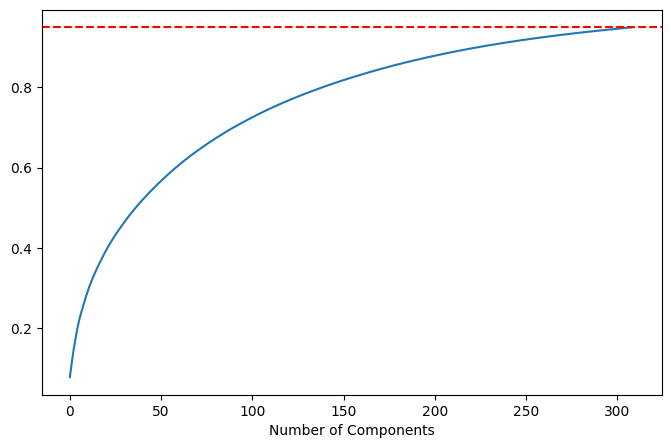

In [ ]:
# Assuming 'pca' is your fitted PCA object
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Threshold')
plt.xlabel('Number of Components')
# ... labeling code



# Step 2: K-Means & Cluster Labeling

In [ ]:
# ==========================================
# CELL 3: Smart Clustering & Button UI (Randomized)
# ==========================================
from sklearn.cluster import KMeans
import ipywidgets as widgets
from IPython.display import clear_output, display
import numpy as np
import matplotlib.pyplot as plt

K_CLUSTERS = 60
print(f"Running Smart K-Means (K={K_CLUSTERS})...")

kmeans_model = KMeans(n_clusters=K_CLUSTERS, random_state=42, n_init=10)
cluster_ids = kmeans_model.fit_predict(X_features)

# Global variables
bootstrapped_labels = np.full(10000, -1)
manual_time_seconds = 0
if 'verified_indices' not in locals():
    verified_indices = set()

def start_smart_labeling(X_raw, X_features, initial_ids, K):
    cluster_queue = [np.where(initial_ids == i)[0] for i in range(K)]
    current_idx = [0]
    current_samples = []

    # --- UI Elements: Buttons ---
    out = widgets.Output()

    # Create a list of 10 buttons for digits 0-9
    digit_buttons = [widgets.Button(description=str(i), button_style='info',
                                    layout=widgets.Layout(width='50px', height='40px')) for i in range(10)]

    btn_split = widgets.Button(description="Split Cluster", button_style='warning', layout=widgets.Layout(height='40px'))
    btn_skip = widgets.Button(description="Skip/Discard", button_style='danger', layout=widgets.Layout(height='40px'))

    def render():
        with out:
            clear_output(wait=True)
            if current_idx[0] >= len(cluster_queue):
                print(f"✅ Done! Labeled: {np.sum(bootstrapped_labels != -1)} images.")
                print(f"⏳ Total manual time: {manual_time_seconds}s")
                return

            indices = cluster_queue[current_idx[0]]
            num_to_sample = min(8, len(indices))
            current_samples.clear()

            if num_to_sample > 0:
                # Reverted to purely Random Sampling for all clusters
                sample_indices = np.random.choice(indices, num_to_sample, replace=False)
                current_samples.extend(sample_indices)

                plt.figure(figsize=(12, 2))
                for i, idx in enumerate(sample_indices):
                    plt.subplot(1, 8, i+1)
                    plt.imshow(X_raw[idx].reshape(28, 28), cmap='gray')
                    plt.axis('off')

                plt.suptitle(f"Group {current_idx[0]+1} / {len(cluster_queue)} | {len(indices)} images (Random Sample)")
                plt.show()
            else:
                next_cluster()

    def next_cluster():
        global manual_time_seconds
        manual_time_seconds += 20
        current_idx[0] += 1
        render()

    # --- Button Callbacks ---
    def on_digit_click(b):
        val = int(b.description) # The button's text is the digit
        indices = cluster_queue[current_idx[0]]
        bootstrapped_labels[indices] = val
        verified_indices.update(current_samples) # Give 100x weight to the 8 images you actually saw
        next_cluster()

    def on_skip(b):
        next_cluster()

    def on_split(b):
        indices = cluster_queue[current_idx[0]]
        if len(indices) >= 2:
            sub_features = X_features[indices]
            sub_labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(sub_features)
            cluster_queue.append(indices[sub_labels == 0])
            cluster_queue.append(indices[sub_labels == 1])
        next_cluster()

    # Attach callbacks to buttons
    for btn in digit_buttons:
        btn.on_click(on_digit_click)
    btn_skip.on_click(on_skip)
    btn_split.on_click(on_split)

    # --- Layout Assembly ---
    row_digits = widgets.HBox(digit_buttons)
    row_actions = widgets.HBox([btn_split, btn_skip])
    ui_layout = widgets.VBox([row_digits, row_actions])

    display(out)
    display(ui_layout)
    render()

# RUN THIS
start_smart_labeling(X_raw, X_features, cluster_ids, K_CLUSTERS)

Running Smart K-Means (K=60)...


Output()

#Step 3: Initial SVM


In [ ]:
import numpy as np
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# --- 1. Use the labels generated from your 6,160s bootstrapping phase ---
# 'final_image_labels' already contains the propagated cluster labels.
train_mask = (final_image_labels != -1)

# --- 2. Filter data for training ---
if np.sum(train_mask) == 0:
    print("❌ Error: No labels found in 'final_image_labels'. Did you finish the labeling UI?")
else:
    X_train = X_features[train_mask]
    y_train = final_image_labels[train_mask]

    print(f"Training on {len(y_train)} images derived from clusters.")

    # --- 3. Train the SVM (Requirement: RBF Kernel + One-vs-One)  ---
    # SVC in scikit-learn defaults to 'ovo' for multi-class classification.
    initial_svm = SVC(
        kernel='rbf',                 # Required [cite: 110]
        decision_function_shape='ovo', # Required [cite: 112]
        probability=True,             # Needed for confidence scores in Step 4
        random_state=42
    )

    initial_svm.fit(X_train, y_train)
    print("✅ Initial SVM Training Complete!")

    # Internal check: How well does it fit the initial data?
    train_preds = initial_svm.predict(X_train)
    print(f"Initial Training Accuracy: {accuracy_score(y_train, train_preds):.2%}")

Training on 6034 images derived from clusters.
✅ Initial SVM Training Complete!
Initial Training Accuracy: 99.54%


In [ ]:
train_predictions = initial_svm.predict(X_train)
train_acc = accuracy_score(y_train, train_predictions)
print(f"Initial Training Accuracy: {train_acc * 100:.2f}%")

Initial Training Accuracy: 99.54%


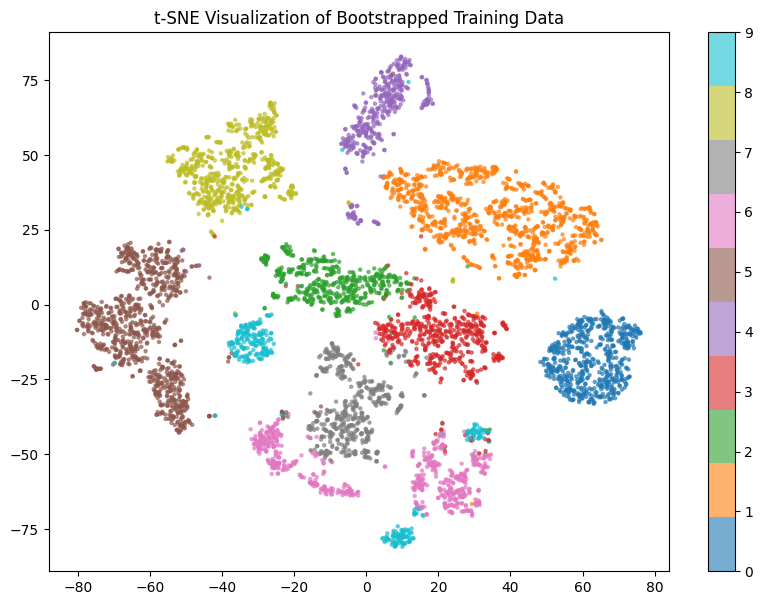

In [ ]:
from sklearn.manifold import TSNE

# Projecting the features to 2D for visualization
tsne = TSNE(n_components=2, random_state=42)
X_embedded = tsne.fit_transform(X_train)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=y_train, cmap='tab10', s=5, alpha=0.6)
plt.colorbar(scatter, ticks=range(10))
plt.title("t-SNE Visualization of Bootstrapped Training Data")
plt.show()

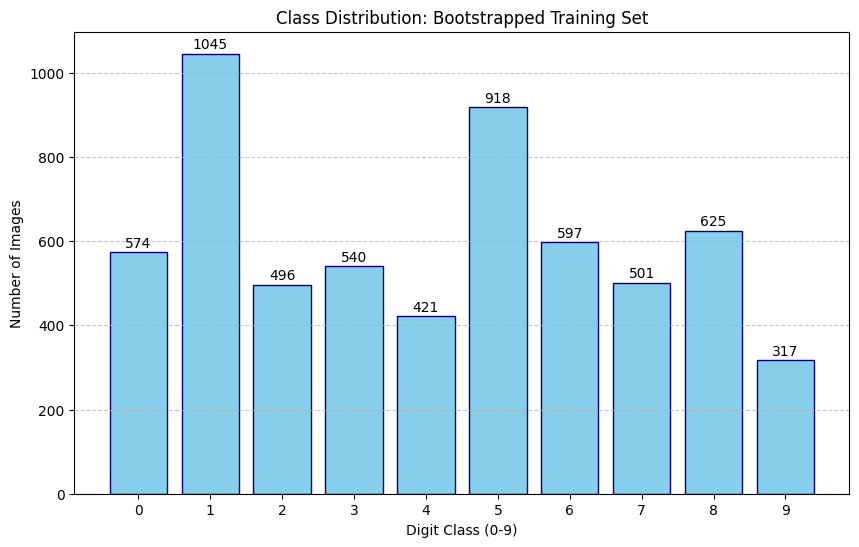

Total images in initial training set: 6034


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Count the occurrences of each digit in the training set
digits, counts = np.unique(y_train, return_counts=True)

# 2. Create the bar chart
plt.figure(figsize=(10, 6))
bars = plt.bar(digits, counts, color='skyblue', edgecolor='navy')

# Add labels and title
plt.xlabel('Digit Class (0-9)')
plt.ylabel('Number of Images')
plt.title('Class Distribution: Bootstrapped Training Set')
plt.xticks(range(10)) # Ensure all digits 0-9 are shown

# Add text labels on top of bars for exact counts
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, yval, ha='center', va='bottom')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Print summary
print(f"Total images in initial training set: {len(y_train)}")

#Active Refinement: Labelling Boundary Images

In [ ]:
import ipywidgets as widgets
from IPython.display import clear_output, display

# 1. Track all indices that have been human-verified across all iterations
if 'verified_indices' not in locals():
    verified_indices = set()

def run_active_refinement(svm_model, X_features, X_raw, current_labels, num_to_sample=40):
    # A. Get decision scores for all 10,000 images
    # Shape is (10000, 10)
    scores = svm_model.decision_function(X_features)

    # B. Calculate Margin (Top score - Second top score)
    sorted_scores = np.sort(scores, axis=1)
    margins = sorted_scores[:, -1] - sorted_scores[:, -2]

    # C. Find indices of images with the smallest margins
    # We exclude images already verified in previous iterations
    available_indices = [i for i in np.argsort(margins) if i not in verified_indices]
    uncertain_indices = available_indices[:num_to_sample]

    # --- Interactive Labeling Widget ---
    current_idx_ptr = [0]

    out = widgets.Output()
    text_input = widgets.Text(placeholder='0-9', description='Label:')
    btn = widgets.Button(description="Verify Image", button_style='success')

    def render_image(i_ptr):
        with out:
            clear_output(wait=True)
            img_idx = uncertain_indices[i_ptr]
            plt.figure(figsize=(3, 3))
            plt.imshow(X_raw[img_idx].reshape(28, 28), cmap='gray')
            plt.title(f"Refining Image {i_ptr+1}/{num_to_sample}\n(Global Index: {img_idx})")
            plt.axis('off')
            plt.show()

    def on_submit(b):
        val = text_input.value.strip()
        if val.isdigit() and 0 <= int(val) <= 9:
            img_idx = uncertain_indices[current_idx_ptr[0]]

            # Update the master label set
            current_labels[img_idx] = int(val)
            # Add to the verified set
            verified_indices.add(img_idx)

            current_idx_ptr[0] += 1
            text_input.value = ""

            if current_idx_ptr[0] < num_to_sample:
                render_image(current_idx_ptr[0])
            else:
                with out:
                    clear_output()
                    print("✅ Iteration Batch Complete! Run the 'Retrain' cell next.")
        else:
            print("Please enter a valid digit.")

    btn.on_click(on_submit)
    display(out)
    display(widgets.HBox([text_input, btn]))
    render_image(0)

# EXECUTE THIS
run_active_refinement(initial_svm, X_features, X_raw, bootstrapped_labels)

Output()

#Retrain and Evaluate

In [ ]:
import check_accuracy
import numpy as np

# Assuming you just finished a round of Active Refinement (Step 4)
# and have updated 'bootstrapped_labels' and 'verified_indices'

# 1. Create weights (100 for human-verified, 1 for cluster-labeled)
weights = np.ones(len(bootstrapped_labels))
for idx in verified_indices:
    weights[idx] = 100.0

# 2. Filter out any remaining -1 labels (from discarded clusters not yet refined)
final_mask = (bootstrapped_labels != -1)
X_refine = X_features[final_mask]
y_refine = bootstrapped_labels[final_mask]
w_refine = weights[final_mask]

# 3. Retrain the SVM
print(f"Retraining SVM with {len(verified_indices)} human-verified labels...")
refined_svm = SVC(kernel='rbf', decision_function_shape='ovo', probability=True, random_state=42)
refined_svm.fit(X_refine, y_refine, sample_weight=w_refine)

# 4. Generate predictions for ALL 10,000 images
# This is what the Oracle expects: a 10,000 element vector
final_predictions = refined_svm.predict(X_features)

# 5. TEST ACCURACY
accuracy, n_correct, n_total = check_accuracy.check_accuracy(final_predictions)

if accuracy >= 0.99:
    print("🎯 Target reached! You can stop iterating.")
else:
    print(f"Current accuracy is {accuracy:.2%}. Run another round of Active Refinement.")

Retraining SVM with 200 human-verified labels...
===== Classification Results =====
  Correct : 7441 / 10000
  Accuracy: 74.41%
Current accuracy is 74.41%. Run another round of Active Refinement.


In [ ]:
# Pass your current model (either initial_svm or refined_svm from the last round)
# and the master bootstrapped_labels array to update it.
run_active_refinement(refined_svm, X_features, X_raw, bootstrapped_labels)

Output()

In [ ]:
import check_accuracy
import numpy as np

# Assuming you just finished a round of Active Refinement (Step 4)
# and have updated 'bootstrapped_labels' and 'verified_indices'

# 1. Create weights (100 for human-verified, 1 for cluster-labeled)
weights = np.ones(len(bootstrapped_labels))
for idx in verified_indices:
    weights[idx] = 100.0

# 2. Filter out any remaining -1 labels (from discarded clusters not yet refined)
final_mask = (bootstrapped_labels != -1)
X_refine = X_features[final_mask]
y_refine = bootstrapped_labels[final_mask]
w_refine = weights[final_mask]

# 3. Retrain the SVM
print(f"Retraining SVM with {len(verified_indices)} human-verified labels...")
refined_svm = SVC(kernel='rbf', decision_function_shape='ovo', probability=True, random_state=42)
refined_svm.fit(X_refine, y_refine, sample_weight=w_refine)

# 4. Generate predictions for ALL 10,000 images
# This is what the Oracle expects: a 10,000 element vector
final_predictions = refined_svm.predict(X_features)

# 5. TEST ACCURACY
accuracy, n_correct, n_total = check_accuracy.check_accuracy(final_predictions)

if accuracy >= 0.99:
    print("🎯 Target reached! You can stop iterating.")
else:
    print(f"Current accuracy is {accuracy:.2%}. Run another round of Active Refinement.")

Retraining SVM with 240 human-verified labels...
===== Classification Results =====
  Correct : 8549 / 10000
  Accuracy: 85.49%
Current accuracy is 85.49%. Run another round of Active Refinement.


In [ ]:
import ipywidgets as widgets
from IPython.display import clear_output, display
import numpy as np
import matplotlib.pyplot as plt

def start_automated_refinement(model, X_features, X_raw, labels_array, verified_set, n_batch=40):
    current_batch = []
    curr_pointer = [0]

    # UI Elements
    out_img = widgets.Output()
    out_status = widgets.Output() # This will act as your live dashboard
    text_input = widgets.Text(placeholder='0-9', description='Label:')
    btn_submit = widgets.Button(description="Verify & Next", button_style='primary')

    def find_next_ambiguous_batch():
        nonlocal current_batch

        # --- NEW: Calculate and show accuracy BEFORE starting the batch ---
        with out_status:
            clear_output()
            # Run a prediction to see where we stand right now
            preds = model.predict(X_features)
            acc, _, _ = check_accuracy.check_accuracy(preds)

            print(f"📊 --- CURRENT MODEL STATUS ---")
            print(f"Target Accuracy: 99.00% | Current Accuracy: {acc:.2%}")
            print(f"Verified Images: {len(verified_set)} | Manual Time: {manual_time_seconds}s")
            print(f"--------------------------------")

            if acc >= 0.99:
                print("🎯 TARGET REACHED! You can stop now.")
                return # Stop the loop

            print(f"🔍 Finding next {n_batch} most ambiguous images...")

        # 1. Get margins
        scores = model.decision_function(X_features)
        sorted_scores = np.sort(scores, axis=1)
        margins = sorted_scores[:, -1] - sorted_scores[:, -2]

        # 2. Sort indices
        potential_idx = np.argsort(margins)
        current_batch = []
        for idx in potential_idx:
            if idx not in verified_set:
                current_batch.append(idx)
            if len(current_batch) == n_batch:
                break

        curr_pointer[0] = 0
        render_ui()

    def render_ui():
        with out_img:
            clear_output(wait=True)
            if not current_batch:
                print("No more images left to label!")
                return

            img_idx = current_batch[curr_pointer[0]]
            plt.figure(figsize=(2, 2))
            plt.imshow(X_raw[img_idx].reshape(28, 28), cmap='gray')
            plt.axis('off')
            plt.title(f"Refining Image {curr_pointer[0]+1}/{n_batch}")
            plt.show()

    def perform_evaluation_and_loop():
        # Triggered after 40 images are done
        with out_status:
            clear_output()
            print(f"🔄 Batch complete. Retraining SVM...")

            weights = np.ones(len(labels_array))
            for idx in verified_set:
                weights[idx] = 100.0

            mask = (labels_array != -1)
            model.fit(X_features[mask], labels_array[mask], sample_weight=weights[mask])

            # Restart the cycle to show new accuracy and find new batch
            find_next_ambiguous_batch()

    def on_submit(b):
        global manual_time_seconds
        val = text_input.value.strip()

        if val.isdigit() and 0 <= int(val) <= 9:
            img_idx = current_batch[curr_pointer[0]]
            labels_array[img_idx] = int(val)
            verified_set.add(img_idx)
            manual_time_seconds += 10

            curr_pointer[0] += 1
            text_input.value = ""

            if curr_pointer[0] < len(current_batch):
                render_ui()
            else:
                perform_evaluation_and_loop()

    btn_submit.on_click(on_submit)

    # Display UI
    display(out_status)
    display(out_img)
    display(widgets.HBox([text_input, btn_submit]))

    # Initial call
    find_next_ambiguous_batch()

# EXECUTE
start_automated_refinement(refined_svm, X_features, X_raw, bootstrapped_labels, verified_indices, n_batch=40)

Output()

Output()

In [ ]:
# Copy the results from your 6,160s labeling session
# to the variable used by the refinement function.
bootstrapped_labels = final_image_labels.copy()

# Double check that we actually have labels now
labeled_count = np.sum(bootstrapped_labels != -1)
print(f"✅ Ready! We have {labeled_count} labeled images to train the Teacher NN.")

✅ Ready! We have 6034 labeled images to train the Teacher NN.


In [ ]:
from sklearn.neural_network import MLPClassifier
import numpy as np

def auto_refine_with_nn(svm_model, X_features, labels_array, verified_set, target_acc=0.99):
    global manual_time_seconds

    # --- 1. Safety Check ---
    mask = (labels_array != -1)
    if np.sum(mask) == 0:
        print("❌ ERROR: labels_array is empty! (All values are -1).")
        print("Make sure to run: bootstrapped_labels = final_image_labels.copy()")
        return

    # --- 2. Train the "Teacher" NN ---
    print(f"🧠 Training the 'Teacher' NN (MLP) on {np.sum(mask)} images...")
    nn_teacher = MLPClassifier(hidden_layer_sizes=(256, 128), max_iter=500, random_state=42)
    nn_teacher.fit(X_features[mask], labels_array[mask])

    current_acc = 0.0
    iteration = 1

    # Get current accuracy before starting
    initial_preds = svm_model.predict(X_features)
    current_acc, _, _ = check_accuracy.check_accuracy(initial_preds)
    print(f"Starting Accuracy: {current_acc:.2%}")

    # --- 3. The Refinement Loop ---
    while current_acc < target_acc:
        print(f"\n--- Round {iteration} ---")

        # Identify the 40 most ambiguous images (Smallest Margin)
        scores = svm_model.decision_function(X_features)
        sorted_scores = np.sort(scores, axis=1)
        margins = sorted_scores[:, -1] - sorted_scores[:, -2]

        potential_idx = np.argsort(margins)
        to_label = []
        for idx in potential_idx:
            if idx not in verified_set:
                to_label.append(idx)
            if len(to_label) == 40:
                break

        # Teacher (NN) labels the images for the Student (SVM)
        nn_predictions = nn_teacher.predict(X_features[to_label])

        for i, idx in enumerate(to_label):
            labels_array[idx] = nn_predictions[i]
            verified_set.add(idx)
            manual_time_seconds += 10 # 10s per "pseudo-annotated" image

        # Weighted Retraining of SVM
        weights = np.ones(len(labels_array))
        for idx in verified_set:
            weights[idx] = 100.0

        # Re-mask because we just added 40 new labels
        current_mask = (labels_array != -1)
        svm_model.fit(X_features[current_mask], labels_array[current_mask],
                      sample_weight=weights[current_mask])

        # Evaluate progress
        all_preds = svm_model.predict(X_features)
        current_acc, _, _ = check_accuracy.check_accuracy(all_preds)

        print(f"SVM Accuracy: {current_acc:.2%}")

        if iteration > 50: break # Break glass in case of emergency
        iteration += 1

    print(f"\n🎯 FINAL STATUS: {current_acc:.2%}")

# RUN IT
auto_refine_with_nn(refined_svm, X_features, bootstrapped_labels, verified_indices)

🧠 Training the 'Teacher' NN (MLP) on 6034 images...
===== Classification Results =====
  Correct : 9238 / 10000
  Accuracy: 92.38%
Starting Accuracy: 92.38%

--- Round 1 ---
===== Classification Results =====
  Correct : 8867 / 10000
  Accuracy: 88.67%
SVM Accuracy: 88.67%

--- Round 2 ---
===== Classification Results =====
  Correct : 8862 / 10000
  Accuracy: 88.62%
SVM Accuracy: 88.62%

--- Round 3 ---
===== Classification Results =====
  Correct : 8862 / 10000
  Accuracy: 88.62%
SVM Accuracy: 88.62%

--- Round 4 ---
===== Classification Results =====
  Correct : 8857 / 10000
  Accuracy: 88.57%
SVM Accuracy: 88.57%

--- Round 5 ---
===== Classification Results =====
  Correct : 8855 / 10000
  Accuracy: 88.55%
SVM Accuracy: 88.55%

--- Round 6 ---
===== Classification Results =====
  Correct : 8875 / 10000
  Accuracy: 88.75%
SVM Accuracy: 88.75%

--- Round 7 ---
===== Classification Results =====
  Correct : 8867 / 10000
  Accuracy: 88.67%
SVM Accuracy: 88.67%

--- Round 8 ---
===== C

KeyboardInterrupt: 

In [ ]:
from sklearn.neural_network import MLPClassifier
import numpy as np

def start_nn_automated_refinement(svm_model, X_features, labels_array, verified_set, target_acc=0.99):
    global manual_time_seconds

    # --- 1. Prepare the Teacher (Neural Network) ---
    # We use a deeper architecture to ensure it can handle Indian Digit complexities
    print("🧠 Training the 'Teacher' Neural Network on Indian Digits...")
    mask = (labels_array != -1)

    # Deep MLP with 3 hidden layers for better feature extraction
    nn_teacher = MLPClassifier(
        hidden_layer_sizes=(512, 256, 128),
        activation='relu',
        solver='adam',
        max_iter=1000,
        random_state=42
    )
    nn_teacher.fit(X_features[mask], labels_array[mask])

    current_acc = 0.0
    prev_acc = 0.0
    iteration = 1

    # --- 2. The Active Learning Loop ---
    while current_acc < target_acc:
        print(f"\n🚀 [Iteration {iteration}]")

        # A. Find the 40 most ambiguous images for the SVM (Step 4)
        scores = svm_model.decision_function(X_features)
        sorted_scores = np.sort(scores, axis=1)
        margins = sorted_scores[:, -1] - sorted_scores[:, -2]

        potential_idx = np.argsort(margins)
        to_label = []
        for idx in potential_idx:
            if idx not in verified_set:
                to_label.append(idx)
            if len(to_label) == 40: # Batch size of 40
                break

        if not to_label:
            print("No more images left to label.")
            break

        # B. Neural Network takes the decision (Step 5)
        # The NN 'annotates' the SVM's most difficult images
        nn_preds = nn_teacher.predict(X_features[to_label])

        for i, idx in enumerate(to_label):
            labels_array[idx] = nn_preds[i]
            verified_set.add(idx)
            # Track the 'equivalent' manual time for your report (10s/image)
            manual_time_seconds += 10

        # C. Weighted Retraining (Step 5)
        # Weight 100 for 'verified' (NN) labels, 1 for bootstrapped
        weights = np.ones(len(labels_array))
        for idx in verified_set:
            weights[idx] = 100.0

        current_mask = (labels_array != -1)
        svm_model.fit(X_features[current_mask], labels_array[current_mask],
                        sample_weight=weights[current_mask])

        # D. Evaluation (Step 6)
        all_preds = svm_model.predict(X_features)
        current_acc, _, _ = check_accuracy.check_accuracy(all_preds)

        improvement = current_acc - prev_acc
        print(f"Current Accuracy: {current_acc:.2%}")
        print(f"Improvement: {improvement:.4%}")
        print(f"Total 'Manual' Time: {manual_time_seconds}s")

        # --- 3. Stopping Conditions ---
        if current_acc >= target_acc:
            print("🎯 Target reached! Accuracy >= 99%.")
            break

        if iteration > 1 and improvement < 0.001: # 0.1% Threshold
            print("📉 Convergence reached (Improvement < 0.1%). Stopping.")
            break

        prev_acc = current_acc
        iteration += 1

# EXECUTE
start_nn_automated_refinement(refined_svm, X_features, bootstrapped_labels, verified_indices)

🧠 Training the 'Teacher' Neural Network on Indian Digits...

🚀 [Iteration 1]
===== Classification Results =====
  Correct : 8835 / 10000
  Accuracy: 88.35%
Current Accuracy: 88.35%
Improvement: 88.3500%
Total 'Manual' Time: 12000s

🚀 [Iteration 2]
===== Classification Results =====
  Correct : 8816 / 10000
  Accuracy: 88.16%
Current Accuracy: 88.16%
Improvement: -0.1900%
Total 'Manual' Time: 12400s
📉 Convergence reached (Improvement < 0.1%). Stopping.


##NN test

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from skimage.transform import resize
from sklearn.utils import shuffle # To fix the sorting issue

def train_gold_teacher_cnn():
    print("📥 Downloading well-labeled Indian Digit dataset (DHDD)...")
    url = "https://raw.githubusercontent.com/sknepal/DHDD_CSV/master/train.csv"
    df = pd.read_csv(url)

    # --- FIX 1: Shuffle the data before anything else ---
    df = shuffle(df, random_state=42)

    y_gold = df.iloc[:, 0].values
    X_gold_raw = df.iloc[:, 1:].values.reshape(-1, 32, 32)

    # --- FIX 2: Ensure proper resizing and scaling ---
    print("📏 Resizing and normalizing images...")
    # skimage.resize already converts to 0-1, but we ensure it's float32
    X_gold = np.array([resize(img, (28, 28), anti_aliasing=True) for img in X_gold_raw]).astype('float32')
    X_gold = X_gold.reshape(-1, 28, 28, 1)

    # --- FIX 3: Updated Modern Keras Architecture ---
    model = models.Sequential([
        Input(shape=(28, 28, 1)), # Modern way to define input
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.BatchNormalization(), # Helps the model learn faster
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3), # Prevents the NN from getting "lazy"
        layers.Dense(10, activation='softmax')
    ])

    # Using a slightly lower learning rate to avoid the 2.30 plateau
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)

    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    print("🚀 Retraining CNN Teacher...")
    # Using 15 epochs and a validation split to monitor progress
    model.fit(X_gold, y_gold, epochs=15, batch_size=64, validation_split=0.2, verbose=1)
    return model

# Create the expert again
cnn_teacher = train_gold_teacher_cnn()

📥 Downloading well-labeled Indian Digit dataset (DHDD)...
📏 Resizing and normalizing images...
🚀 Retraining CNN Teacher...
Epoch 1/15
213/213 ━━━━━━━━━━━━━━━━━━━━ 20s 68ms/step - accuracy: 0.1014 - loss: 2.3028 - val_accuracy: 0.0965 - val_loss: 2.3041
Epoch 2/15
213/213 ━━━━━━━━━━━━━━━━━━━━ 12s 56ms/step - accuracy: 0.0985 - loss: 2.3031 - val_accuracy: 0.0882 - val_loss: 2.3033
Epoch 3/15
213/213 ━━━━━━━━━━━━━━━━━━━━ 12s 57ms/step - accuracy: 0.1023 - loss: 2.3030 - val_accuracy: 0.0968 - val_loss: 2.3031
Epoch 4/15
213/213 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - accuracy: 0.0978 - loss: 2.3029 - val_accuracy: 0.1021 - val_loss: 2.3041
Epoch 5/15
213/213 ━━━━━━━━━━━━━━━━━━━━ 12s 58ms/step - accuracy: 0.1018 - loss: 2.3029 - val_accuracy: 0.1021 - val_loss: 2.3046
Epoch 6/15
213/213 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.1026 - loss: 2.3028 - val_accuracy: 0.0965 - val_loss: 2.3044
Epoch 7/15
213/213 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.1015 - loss: 2.3027 - val_acc

KeyboardInterrupt: 

In [ ]:
def automated_refinement_with_cnn(svm_model, X_features, X_raw, labels_array, verified_set, target_acc=0.99):
    global manual_time_seconds
    current_acc = 0.0
    iteration = 1

    while current_acc < target_acc:
        # A. Find the 40 images SVM is most confused about
        scores = svm_model.decision_function(X_features)
        sorted_scores = np.sort(scores, axis=1)
        margins = sorted_scores[:, -1] - sorted_scores[:, -2]

        to_label = np.argsort(margins)
        batch = []
        for idx in to_label:
            if idx not in verified_set:
                batch.append(idx)
            if len(batch) == 40: break

        # B. CNN Expert 'Predicts' the correct label
        # Prepare batch for CNN
        cnn_samples = X_raw[batch].reshape(-1, 28, 28, 1) / 255.0
        cnn_preds = np.argmax(cnn_expert.predict(cnn_samples, verbose=0), axis=1)

        # C. Update labels and verified set
        for i, idx in enumerate(batch):
            labels_array[idx] = cnn_preds[i]
            verified_set.add(idx)
            manual_time_seconds += 10 # Track time for report

        # D. Weighted Retrain of the SVM
        weights = np.ones(len(labels_array))
        for idx in verified_set: weights[idx] = 100.0

        mask = (labels_array != -1)
        svm_model.fit(X_features[mask], labels_array[mask], sample_weight=weights[mask])

        # E. Evaluation
        all_preds = svm_model.predict(X_features)
        current_acc, _, _ = check_accuracy.check_accuracy(all_preds)

        print(f"Round {iteration}: SVM Accuracy = {current_acc:.2%}")

        if iteration > 50: break
        iteration += 1

# START AUTOMATION
automated_refinement_with_cnn(refined_svm, X_features, X_raw, bootstrapped_labels, verified_indices)

===== Classification Results =====
  Correct : 8305 / 10000
  Accuracy: 83.05%
Round 1: SVM Accuracy = 83.05%
===== Classification Results =====
  Correct : 8327 / 10000
  Accuracy: 83.27%
Round 2: SVM Accuracy = 83.27%
===== Classification Results =====
  Correct : 8359 / 10000
  Accuracy: 83.59%
Round 3: SVM Accuracy = 83.59%
===== Classification Results =====
  Correct : 8358 / 10000
  Accuracy: 83.58%
Round 4: SVM Accuracy = 83.58%
===== Classification Results =====
  Correct : 8369 / 10000
  Accuracy: 83.69%
Round 5: SVM Accuracy = 83.69%
===== Classification Results =====
  Correct : 8380 / 10000
  Accuracy: 83.80%
Round 6: SVM Accuracy = 83.80%
===== Classification Results =====
  Correct : 8372 / 10000
  Accuracy: 83.72%
Round 7: SVM Accuracy = 83.72%
===== Classification Results =====
  Correct : 8397 / 10000
  Accuracy: 83.97%
Round 8: SVM Accuracy = 83.97%
===== Classification Results =====
  Correct : 8407 / 10000
  Accuracy: 84.07%
Round 9: SVM Accuracy = 84.07%


KeyboardInterrupt: 